# Resized SEM-NFFA inpainting with the all-ten-category prior

This notebook selects a held-out raw source from the three-class `sem_nffa` test split, resizes the complete frame to 128 x 128, and reconstructs it with the completed ten-category `sem_nffa_all10` prior. It runs independent PnP-Flow tests for every size listed in `MASK_SIZES` at a configurable `(X, Y)` location.

Masks are created after resizing, so their side lengths are exact in model space. The clean resized frame is retained as synthetic ground truth. Mask convention: `known=1` means observed and `missing=True` means reconstructed.

In [19]:
from pathlib import Path
import csv
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torch.nn.functional as F

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks directory.')
os.chdir(repo_root)

from pnpflow.utils import define_model

SOURCE_DATASET_NAME = 'sem_nffa'
MODEL_DATASET_NAME = 'sem_nffa_all10'
RUN_NAME = '20260713_112747_sem_nffa_all10_ot'
CHECKPOINT_PATH = repo_root / 'model' / MODEL_DATASET_NAME / 'ot' / RUN_NAME / 'model_final.pt'
SOURCE_MANIFEST_PATH = repo_root / 'data' / SOURCE_DATASET_NAME / 'source_manifest.csv'
RAW_SEM_ROOT = Path('/data2/marci/bselvaku/nffa_sem/raw_images')
# Image selection: set RAW_SEM_IMAGE_OVERRIDE to choose a specific image.
# It may be an absolute path or a path relative to RAW_SEM_ROOT, for example:
# RAW_SEM_IMAGE_OVERRIDE = 'Particles/L2_example.jpg'
# RAW_SEM_IMAGE_OVERRIDE = Path('/absolute/path/to/image.jpg')
# Leave it as None to select a held-out manifest source with TEST_SOURCE_INDEX.
RAW_SEM_IMAGE_OVERRIDE = '/data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_0a800855e3b88fd72a83fe7dd8257f88.jpg'
TEST_SOURCE_INDEX = 500

with SOURCE_MANIFEST_PATH.open(newline='', encoding='utf-8') as handle:
    manifest_rows = list(csv.DictReader(handle))
test_sources = [row for row in manifest_rows if row['split'] == 'test']
if not test_sources:
    raise RuntimeError(f'No test sources found in {SOURCE_MANIFEST_PATH}')
if RAW_SEM_IMAGE_OVERRIDE is None:
    if not 0 <= TEST_SOURCE_INDEX < len(test_sources):
        raise IndexError(f'TEST_SOURCE_INDEX={TEST_SOURCE_INDEX}; valid range is 0:{len(test_sources)}')
    SOURCE_ROW = test_sources[TEST_SOURCE_INDEX]
    RAW_SEM_IMAGE = RAW_SEM_ROOT / SOURCE_ROW['source']
    IMAGE_SELECTION = f'test manifest index {TEST_SOURCE_INDEX}'
else:
    requested_path = Path(RAW_SEM_IMAGE_OVERRIDE).expanduser()
    RAW_SEM_IMAGE = requested_path if requested_path.is_absolute() else RAW_SEM_ROOT / requested_path
    RAW_SEM_IMAGE = RAW_SEM_IMAGE.resolve()
    try:
        relative_source = RAW_SEM_IMAGE.relative_to(RAW_SEM_ROOT.resolve()).as_posix()
    except ValueError:
        relative_source = RAW_SEM_IMAGE.name
    matching_rows = [row for row in manifest_rows if row['source'] == relative_source]
    SOURCE_ROW = matching_rows[0] if matching_rows else {
        'source': relative_source, 'category': RAW_SEM_IMAGE.parent.name, 'split': 'external/unlisted'
    }
    IMAGE_SELECTION = 'explicit RAW_SEM_IMAGE_OVERRIDE'

MODEL_SIZE = 128
MASK_SIZES = (5, 10, 15, 20 )
MASK_CENTER_XY = (80, 40)  # (X, Y) in the resized 128 x 128 image.
STEPS_PNP = 100
NUM_SAMPLES = 15
LR_PNP = 1.0
NOISE_STD = 0.05  # Reference Gaussian box-inpainting setting.
ALPHA = 0.5       # Reference box-inpainting decay setting.
ADD_OBSERVATION_NOISE = False
BASE_SEED = 0
USE_MULTI_GPU = True

OUTPUT_DIR = (repo_root / 'results' / MODEL_DATASET_NAME / 'ot' /
              'resized_128_multisize_square_inpainting' / RAW_SEM_IMAGE.stem /
              f'center_x{MASK_CENTER_XY[0]}_y{MASK_CENTER_XY[1]}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if RAW_SEM_IMAGE_OVERRIDE is None:
    assert SOURCE_ROW['split'] == 'test'
assert CHECKPOINT_PATH.is_file(), f'Checkpoint not found: {CHECKPOINT_PATH}'
assert RAW_SEM_IMAGE.is_file(), f'Raw SEM image not found: {RAW_SEM_IMAGE}'
print(f'Checkpoint: {CHECKPOINT_PATH}')
print(f'Image selection: {IMAGE_SELECTION}')
print(f'Raw image: {RAW_SEM_IMAGE}')
print(f'Category: {SOURCE_ROW["category"]}; split: {SOURCE_ROW["split"]}')
print(f'Masks: {MASK_SIZES}; center (X, Y): {MASK_CENTER_XY}')
print(f'Output directory: {OUTPUT_DIR}')

Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10/ot/20260713_112747_sem_nffa_all10_ot/model_final.pt
Image selection: explicit RAW_SEM_IMAGE_OVERRIDE
Raw image: /data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_0a800855e3b88fd72a83fe7dd8257f88.jpg
Category: Biological; split: external/unlisted
Masks: (5, 10, 15, 20); center (X, Y): (80, 40)
Output directory: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/resized_128_multisize_square_inpainting/L7_0a800855e3b88fd72a83fe7dd8257f88/center_x80_y40


In [20]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('This PnP-Flow inference notebook requires a CUDA GPU.')

torch.manual_seed(BASE_SEED)
torch.cuda.manual_seed_all(BASE_SEED)

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = MODEL_SIZE

model, _ = define_model(ModelArgs())
state_dict = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.to(device).eval()

gpu_ids = list(range(torch.cuda.device_count()))
if USE_MULTI_GPU and len(gpu_ids) > 1:
    model = torch.nn.DataParallel(model, device_ids=gpu_ids, output_device=gpu_ids[0])
    print(f'Multi-GPU prior sampling enabled on GPUs {gpu_ids}')
else:
    print(f'Single-GPU inference on {torch.cuda.get_device_name(0)}')
print(f'Primary device: {device}')

Multi-GPU prior sampling enabled on GPUs [0, 1, 2, 3]
Primary device: cuda:0


Raw SEM shape: (768, 1024)
Normalization percentiles: low=28, high=255
Resized model input: (128, 128)
5 x 5 model pixels correspond to about 30.0 x 40.0 raw pixels
10 x 10 model pixels correspond to about 60.0 x 80.0 raw pixels
15 x 15 model pixels correspond to about 90.0 x 120.0 raw pixels
20 x 20 model pixels correspond to about 120.0 x 160.0 raw pixels


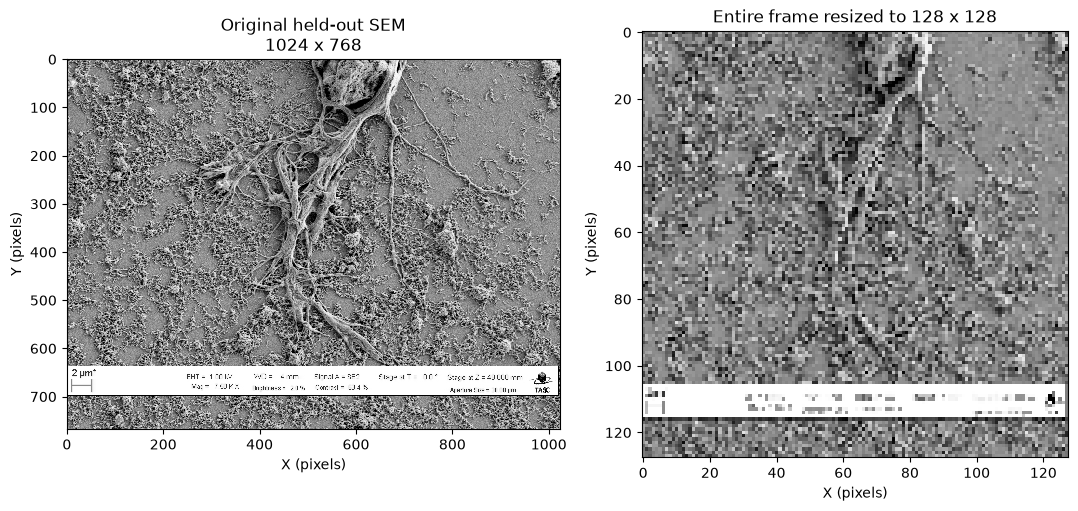

In [21]:
with Image.open(RAW_SEM_IMAGE) as image:
    raw_sem = np.asarray(image.convert('L'), dtype=np.float32)
if raw_sem.ndim != 2 or not np.isfinite(raw_sem).all():
    raise ValueError(f'Expected a finite 2D grayscale frame, got {raw_sem.shape}')

raw_height, raw_width = raw_sem.shape
low, high = np.percentile(raw_sem, (1, 99))
if not high > low:
    raise ValueError('Raw SEM frame has no usable percentile intensity range.')
raw_clipped = np.clip(raw_sem, low, high).astype(np.float32)
raw_norm = (2.0 * (raw_clipped - low) / (high - low) - 1.0).astype(np.float32)

raw_tensor = torch.from_numpy(raw_norm)[None, None]
clean_128 = F.interpolate(
    raw_tensor, size=(MODEL_SIZE, MODEL_SIZE), mode='bilinear', align_corners=False
)[0, 0].numpy().astype(np.float32)

scale_y = raw_height / MODEL_SIZE
scale_x = raw_width / MODEL_SIZE
print(f'Raw SEM shape: {raw_sem.shape}')
print(f'Normalization percentiles: low={low:.5g}, high={high:.5g}')
print(f'Resized model input: {clean_128.shape}')
for size in MASK_SIZES:
    print(f'{size} x {size} model pixels correspond to about {size * scale_y:.1f} x {size * scale_x:.1f} raw pixels')

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
axes[0].imshow(raw_clipped, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title(f'Original held-out SEM\n{raw_width} x {raw_height}')
axes[1].imshow(clean_128, cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
axes[1].set_title('Entire frame resized to 128 x 128')
for ax in axes:
    ax.set_xlabel('X (pixels)')
    ax.set_ylabel('Y (pixels)')
plt.show()

In [22]:
def missing_mask_at_center(size, center_xy):
    if not 0 < size < MODEL_SIZE:
        raise ValueError(f'Mask size must be between 1 and {MODEL_SIZE - 1}, got {size}.')
    center_x, center_y = map(int, center_xy)
    top = center_y - size // 2
    left = center_x - size // 2
    bottom = top + size
    right = left + size
    if not (0 <= top < bottom <= MODEL_SIZE and 0 <= left < right <= MODEL_SIZE):
        raise ValueError(f'{size} x {size} mask centered at {center_xy} is outside the 128 x 128 image.')
    mask = np.zeros((MODEL_SIZE, MODEL_SIZE), dtype=bool)
    mask[top:bottom, left:right] = True
    return mask, (top, left, bottom, right)

@torch.inference_mode()
def pnp_flow_inpaint(clean_image, missing_mask, seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    clean = torch.from_numpy(clean_image)[None, None].to(device=device, dtype=torch.float32)
    missing = torch.from_numpy(missing_mask.astype(np.float32))[None, None].to(device)
    known = 1.0 - missing
    observed = known * clean
    if ADD_OBSERVATION_NOISE:
        observed = (observed + known * torch.randn_like(observed) * NOISE_STD).clamp(-1, 1)

    x = observed.clone()
    lr = (NOISE_STD ** 2) * LR_PNP
    start = time.perf_counter()
    for iteration in range(STEPS_PNP):
        t = torch.full((1,), iteration / STEPS_PNP, device=device)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(1, 1, 1, 1)
        data_gradient = known * (known * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient

        t_samples = t.expand(NUM_SAMPLES)
        t_view = t_samples.view(NUM_SAMPLES, 1, 1, 1)
        z_samples = z.expand(NUM_SAMPLES, -1, -1, -1)
        z_tilde = t_view * z_samples + (1.0 - t_view) * torch.randn_like(z_samples)
        velocity = model(z_tilde, t_samples)
        candidates = z_tilde + (1.0 - t_view) * velocity
        x_new = candidates.mean(dim=0, keepdim=True)
        x = known * observed + missing * x_new

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return observed[0, 0].cpu().numpy(), x[0, 0].clamp(-1, 1).cpu().numpy(), elapsed

results = {}
for index, size in enumerate(MASK_SIZES):
    missing, bounds = missing_mask_at_center(size, MASK_CENTER_XY)
    observed, reconstruction, elapsed = pnp_flow_inpaint(clean_128, missing, BASE_SEED + index)
    results[size] = {
        'missing': missing, 'bounds': bounds, 'observed': observed,
        'reconstruction': reconstruction, 'seconds': elapsed,
    }
    print(f'Completed {size} x {size} mask in {elapsed:.2f} seconds')

Completed 5 x 5 mask in 20.17 seconds
Completed 10 x 10 mask in 19.40 seconds
Completed 15 x 15 mask in 19.99 seconds
Completed 20 x 20 mask in 19.59 seconds


In [23]:
def missing_metrics(reference, estimate, missing):
    error = estimate[missing] - reference[missing]
    mse = float(np.mean(error ** 2))
    return {
        'missing_pixels': int(missing.sum()),
        'missing_fraction': float(missing.mean()),
        'missing_mae_normalized': float(np.mean(np.abs(error))),
        'missing_rmse_normalized': float(np.sqrt(mse)),
        'missing_psnr_normalized_0_1': float(10.0 * np.log10(1.0 / max(mse / 4.0, 1e-12))),
    }

summary = {
    'raw_image': str(RAW_SEM_IMAGE),
    'source_relative_path': SOURCE_ROW['source'],
    'source_category': SOURCE_ROW['category'],
    'source_split': SOURCE_ROW['split'],
    'checkpoint': str(CHECKPOINT_PATH),
    'raw_shape': [int(raw_height), int(raw_width)],
    'model_shape': [MODEL_SIZE, MODEL_SIZE],
    'mask_center_xy': list(MASK_CENTER_XY),
    'normalization_low': float(low),
    'normalization_high': float(high),
    'steps_pnp': STEPS_PNP, 'num_samples': NUM_SAMPLES,
    'noise_std': NOISE_STD, 'alpha': ALPHA,
    'hard_known_pixel_consistency': True,
    'add_observation_noise': ADD_OBSERVATION_NOISE,
    'masks': {},
}

np.save(OUTPUT_DIR / 'clean_sem_resized_128_normalized_float32.npy', clean_128.astype(np.float32))
for size, item in results.items():
    metrics = missing_metrics(clean_128, item['reconstruction'], item['missing'])
    metrics['seconds'] = float(item['seconds'])
    metrics['bounds_top_left_bottom_right'] = list(map(int, item['bounds']))
    summary['masks'][str(size)] = metrics
    np.save(OUTPUT_DIR / f'missing_mask_128_{size}x{size}_uint8.npy', item['missing'].astype(np.uint8))
    np.save(OUTPUT_DIR / f'observed_128_{size}x{size}_normalized_float32.npy', item['observed'].astype(np.float32))
    np.save(OUTPUT_DIR / f'reconstruction_128_{size}x{size}_normalized_float32.npy', item['reconstruction'].astype(np.float32))
    print(f'{size} x {size}: PSNR={metrics["missing_psnr_normalized_0_1"]:.3f} dB, MAE={metrics["missing_mae_normalized"]:.5f}')
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as handle:
    json.dump(summary, handle, indent=2)
print(f'Saved arrays and metrics to: {OUTPUT_DIR}')

5 x 5: PSNR=17.052 dB, MAE=0.21327
10 x 10: PSNR=16.509 dB, MAE=0.23618
15 x 15: PSNR=15.987 dB, MAE=0.24126
20 x 20: PSNR=15.794 dB, MAE=0.25338
Saved arrays and metrics to: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/resized_128_multisize_square_inpainting/L7_0a800855e3b88fd72a83fe7dd8257f88/center_x80_y40


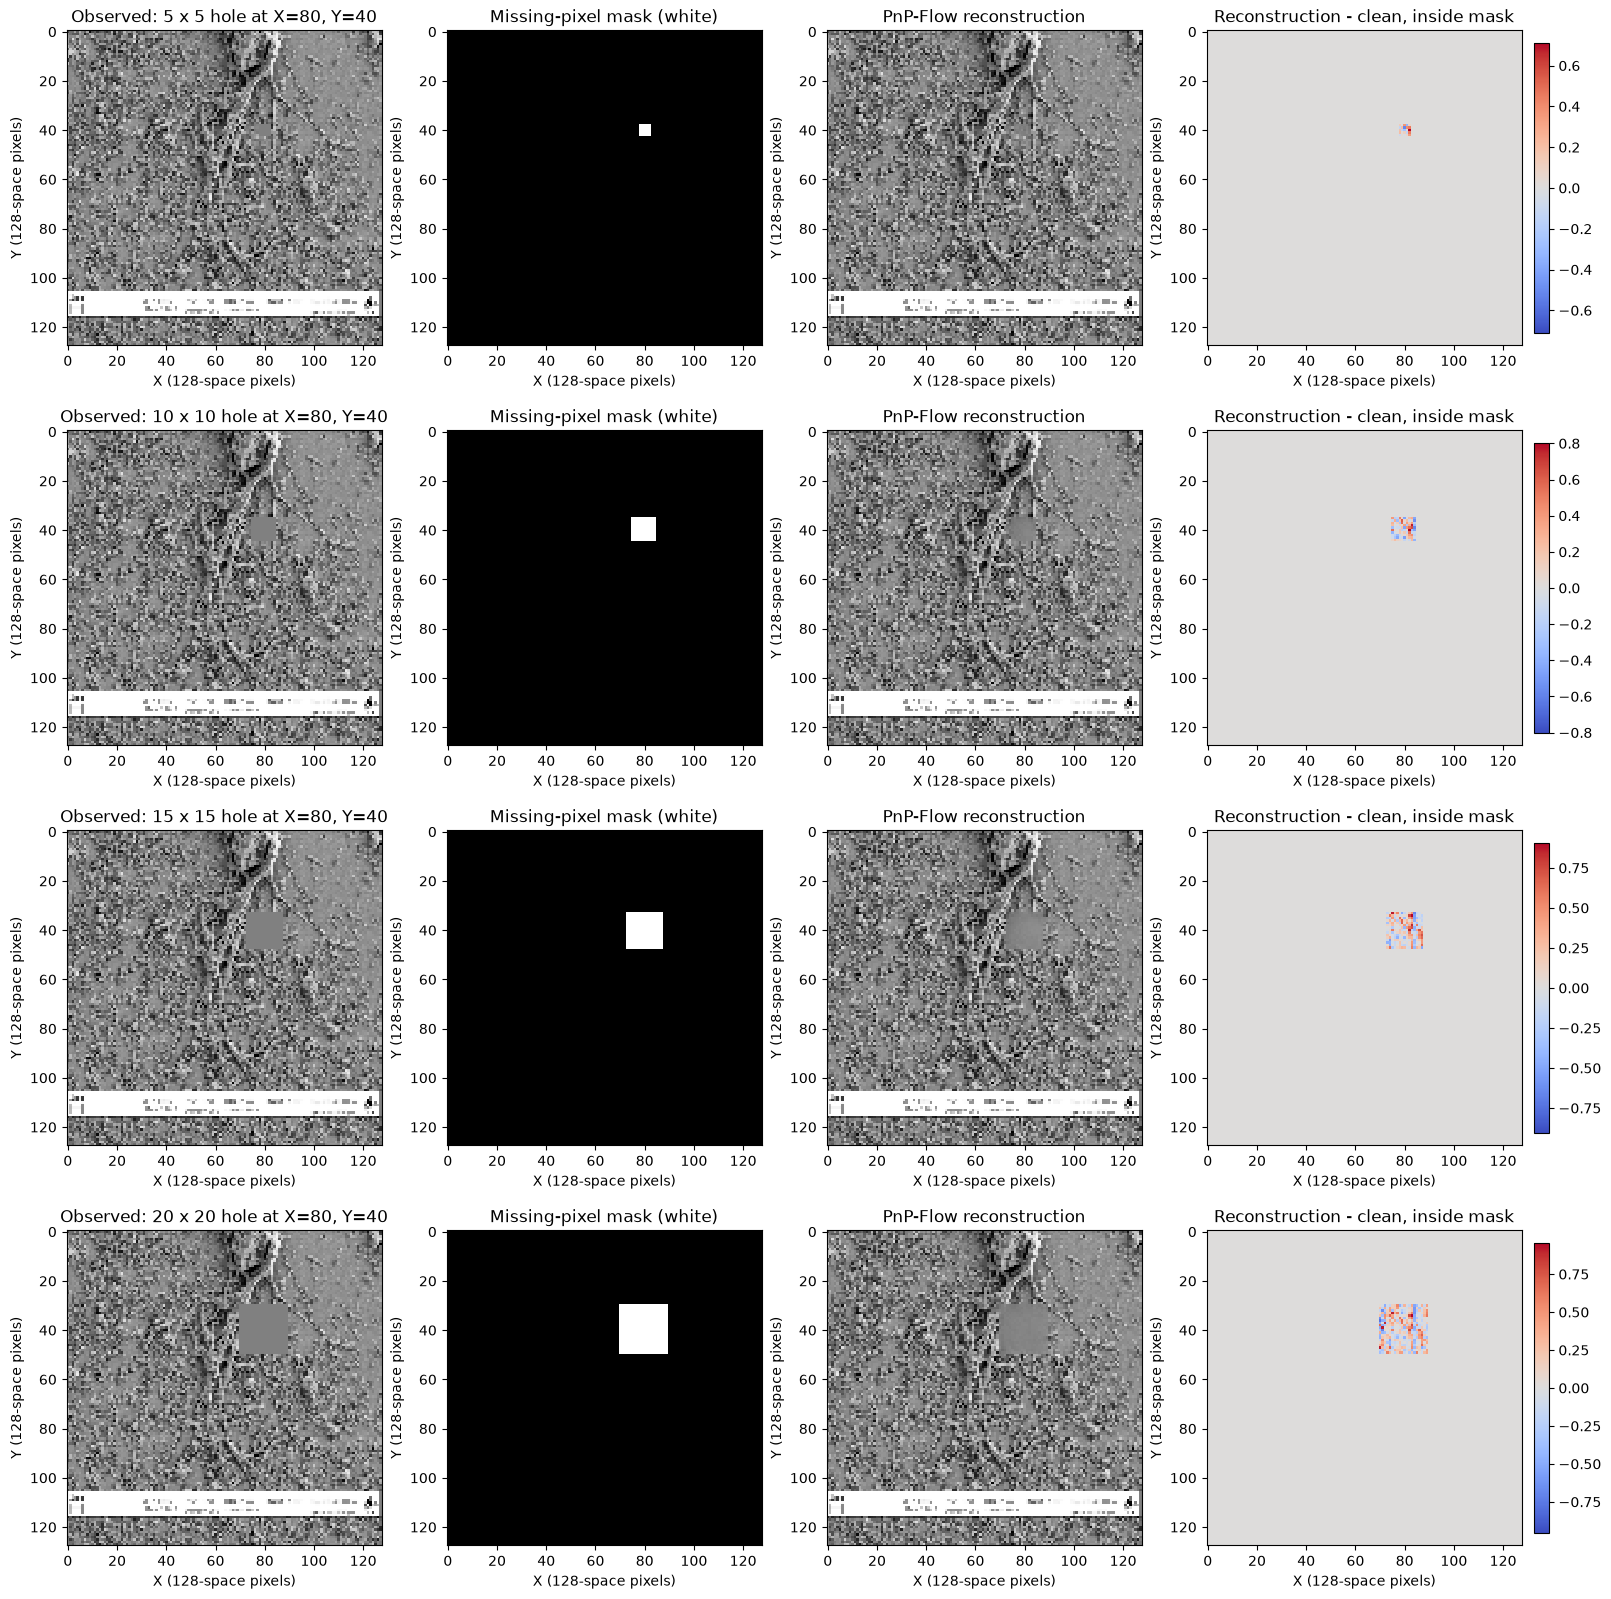

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/resized_128_multisize_square_inpainting/L7_0a800855e3b88fd72a83fe7dd8257f88/center_x80_y40/all_mask_sizes_four_panel_comparison.png


In [24]:
fig, axes = plt.subplots(len(MASK_SIZES), 4, figsize=(16, 4 * len(MASK_SIZES)), constrained_layout=True)
for row, size in enumerate(MASK_SIZES):
    item = results[size]
    missing = item['missing']
    change = np.zeros_like(clean_128)
    change[missing] = item['reconstruction'][missing] - clean_128[missing]
    axes[row, 0].imshow(item['observed'], cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
    axes[row, 0].set_title(f'Observed: {size} x {size} hole at X={MASK_CENTER_XY[0]}, Y={MASK_CENTER_XY[1]}')
    axes[row, 1].imshow(missing, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes[row, 1].set_title('Missing-pixel mask (white)')
    axes[row, 2].imshow(item['reconstruction'], cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
    axes[row, 2].set_title('PnP-Flow reconstruction')
    limit = max(float(np.max(np.abs(change))), 1e-6)
    image = axes[row, 3].imshow(change, cmap='coolwarm', vmin=-limit, vmax=limit, interpolation='nearest')
    axes[row, 3].set_title('Reconstruction - clean, inside mask')
    fig.colorbar(image, ax=axes[row, 3], fraction=0.046, pad=0.04)
    for ax in axes[row]:
        ax.set_xlabel('X (128-space pixels)')
        ax.set_ylabel('Y (128-space pixels)')
comparison_path = OUTPUT_DIR / 'all_mask_sizes_four_panel_comparison.png'
fig.savefig(comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {comparison_path}')

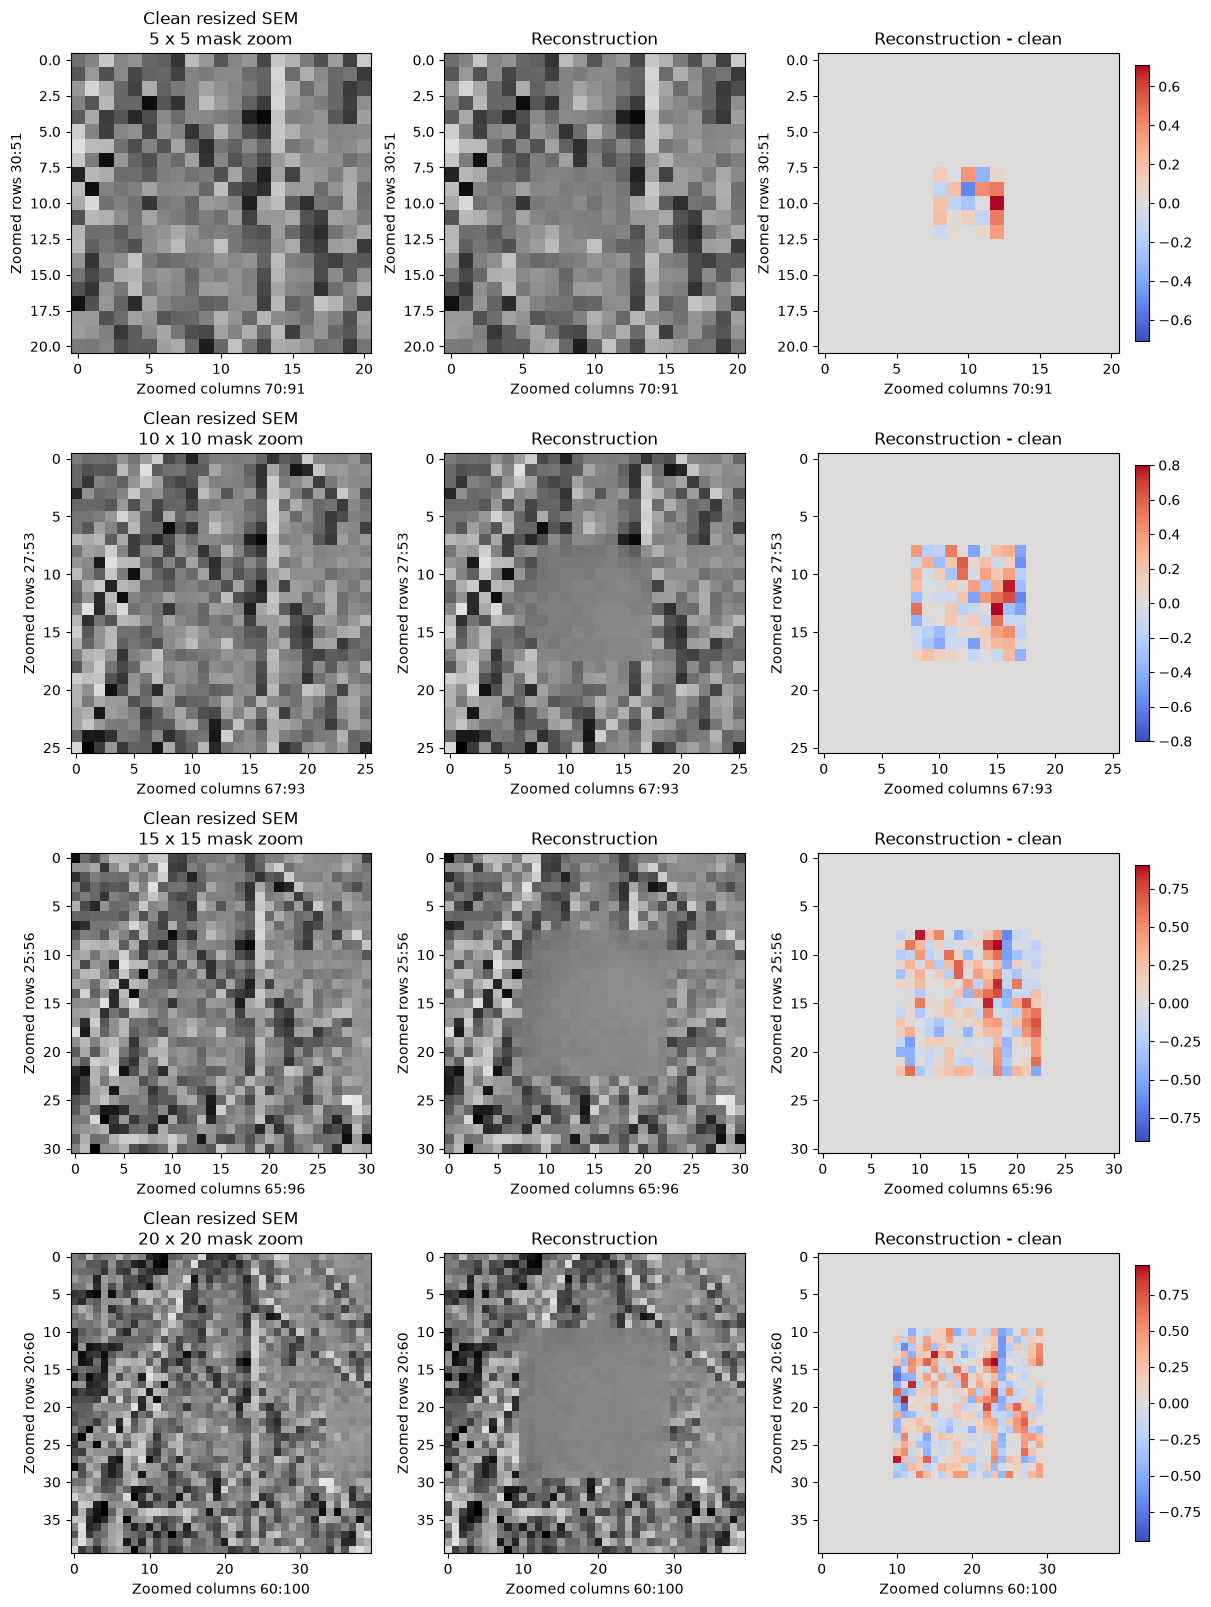

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/resized_128_multisize_square_inpainting/L7_0a800855e3b88fd72a83fe7dd8257f88/center_x80_y40/all_mask_sizes_zoomed_clean_vs_reconstruction.png


In [25]:
fig, axes = plt.subplots(len(MASK_SIZES), 3, figsize=(12, 4 * len(MASK_SIZES)), constrained_layout=True)
for row, size in enumerate(MASK_SIZES):
    item = results[size]
    top, left, bottom, right = item['bounds']
    margin = max(8, size // 2)
    y0, y1 = max(0, top - margin), min(MODEL_SIZE, bottom + margin)
    x0, x1 = max(0, left - margin), min(MODEL_SIZE, right + margin)
    target = np.s_[y0:y1, x0:x1]
    difference = item['reconstruction'][target] - clean_128[target]
    limit = max(float(np.max(np.abs(difference))), 1e-6)
    axes[row, 0].imshow(clean_128[target], cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
    axes[row, 0].set_title(f'Clean resized SEM\n{size} x {size} mask zoom')
    axes[row, 1].imshow(item['reconstruction'][target], cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
    axes[row, 1].set_title('Reconstruction')
    image = axes[row, 2].imshow(difference, cmap='coolwarm', vmin=-limit, vmax=limit, interpolation='nearest')
    axes[row, 2].set_title('Reconstruction - clean')
    fig.colorbar(image, ax=axes[row, 2], fraction=0.046, pad=0.04)
    for ax in axes[row]:
        ax.set_xlabel(f'Zoomed columns {x0}:{x1}')
        ax.set_ylabel(f'Zoomed rows {y0}:{y1}')
zoom_path = OUTPUT_DIR / 'all_mask_sizes_zoomed_clean_vs_reconstruction.png'
fig.savefig(zoom_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {zoom_path}')

## Interpretation

All mask sizes and center coordinates are measured in the resized 128 x 128 image. This tests a single global resized view, not native-resolution tiled reconstruction. Use `TEST_SOURCE_INDEX` to select another held-out raw source, or set `RAW_SEM_IMAGE_OVERRIDE` to an absolute path or a path relative to `RAW_SEM_ROOT`. Change `MASK_CENTER_XY` to move all four masks while retaining directly comparable sizes.